# Assignment 1: plots

## Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = "results"
PLOTS = "results/plots"
os.makedirs(PLOTS, exist_ok=True)

SKIP = 5  # skip the first frames of each run (warm-up)

BLUE, ORANGE, GREEN, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e6e6e1"
plt.rcParams["axes.axisbelow"] = True


def load(filename):
    df = pd.read_csv(os.path.join(RESULTS, filename))
    df = df.iloc[SKIP:]
    df["frame_ms"] = 1000 / df["fps"]
    return df


def save(fig, filename):
    fig.savefig(os.path.join(PLOTS, filename), dpi=150, bbox_inches="tight")

## 1. Time per frame
Mean and median time per frame for each version.

In [2]:
runs = {
    "none, display":         "03_none_display.csv",
    "brightest, display":    "04_brightest_display.csv",
    "reddest, display":      "05_reddest_display.csv",
    "none, no display":      "06_none_nodisplay.csv",
    "brightest, no display": "07_brightest_nodisplay.csv",
    "reddest, no display":   "08_reddest_nodisplay.csv",
}

names = list(runs.keys())
mean_ms = [load(f)["frame_ms"].mean() for f in runs.values()]
median_ms = [load(f)["frame_ms"].median() for f in runs.values()]

table = pd.DataFrame({"mean_ms": mean_ms, "median_ms": median_ms}, index=names)
table["fps"] = 1000 / table["mean_ms"]
table.round(2)

,mean_ms,median_ms,fps
"none, display",33.30,3.65,30.03
"brightest, display",33.30,3.88,30.03
"reddest, display",33.31,7.19,30.02
"none, no display",33.30,2.19,30.03
"brightest, no display",33.30,2.09,30.03
"reddest, no display",33.28,5.20,30.04


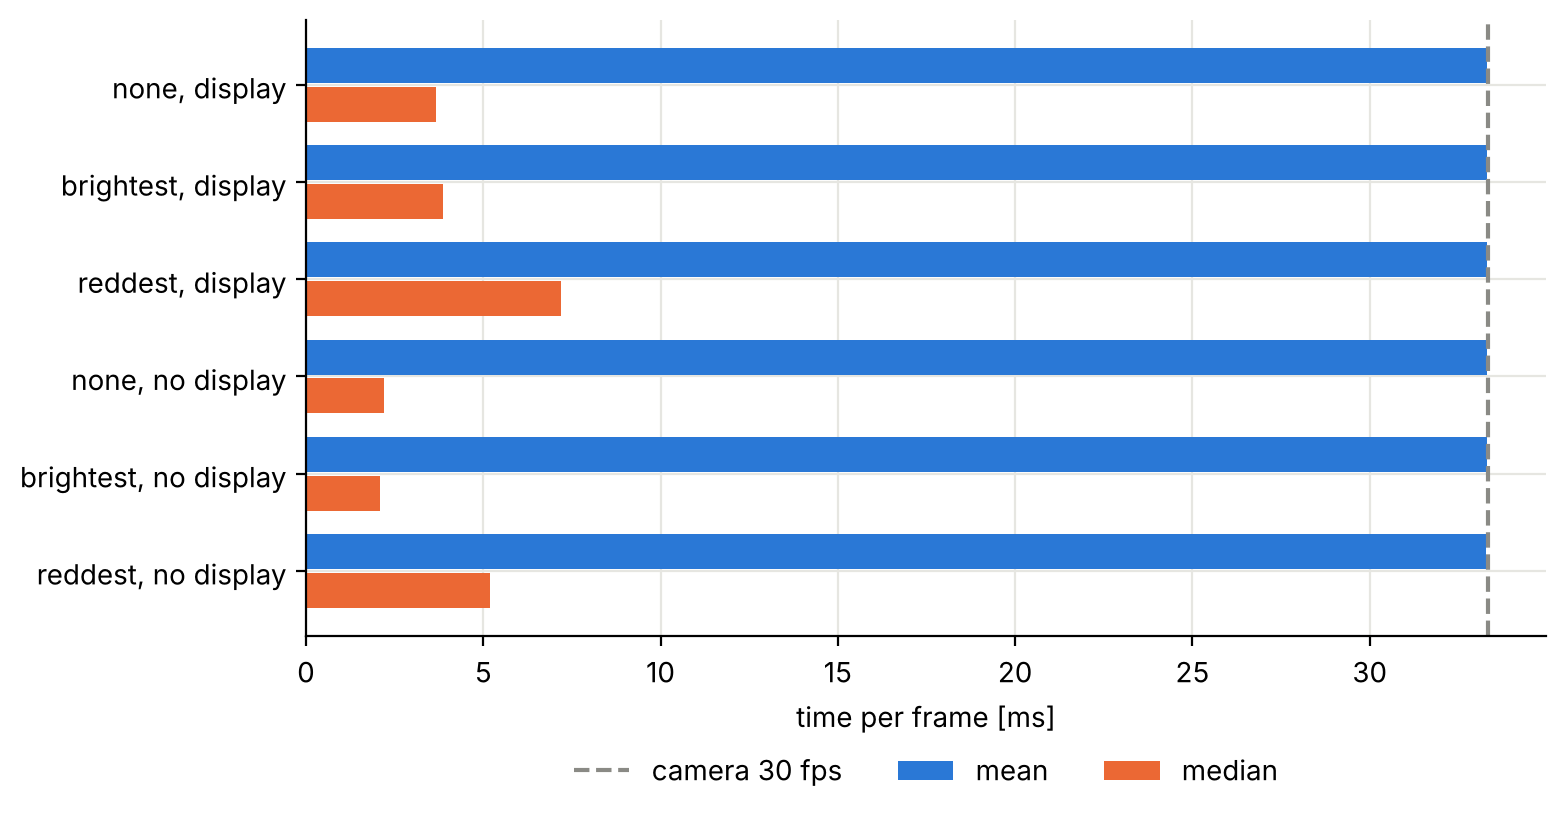

In [3]:
y = np.arange(len(names))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(y - 0.2, mean_ms, height=0.36, color=BLUE, label="mean")
ax.barh(y + 0.2, median_ms, height=0.36, color=ORANGE, label="median")
ax.axvline(1000 / 30, color=GRAY, linestyle="--", label="camera 30 fps")
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlabel("time per frame [ms]")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
save(fig, "1_time_per_frame.png")
plt.show()

## 2. Loop-pass pattern
Time of each loop pass, first 60 passes, no detection and no display.

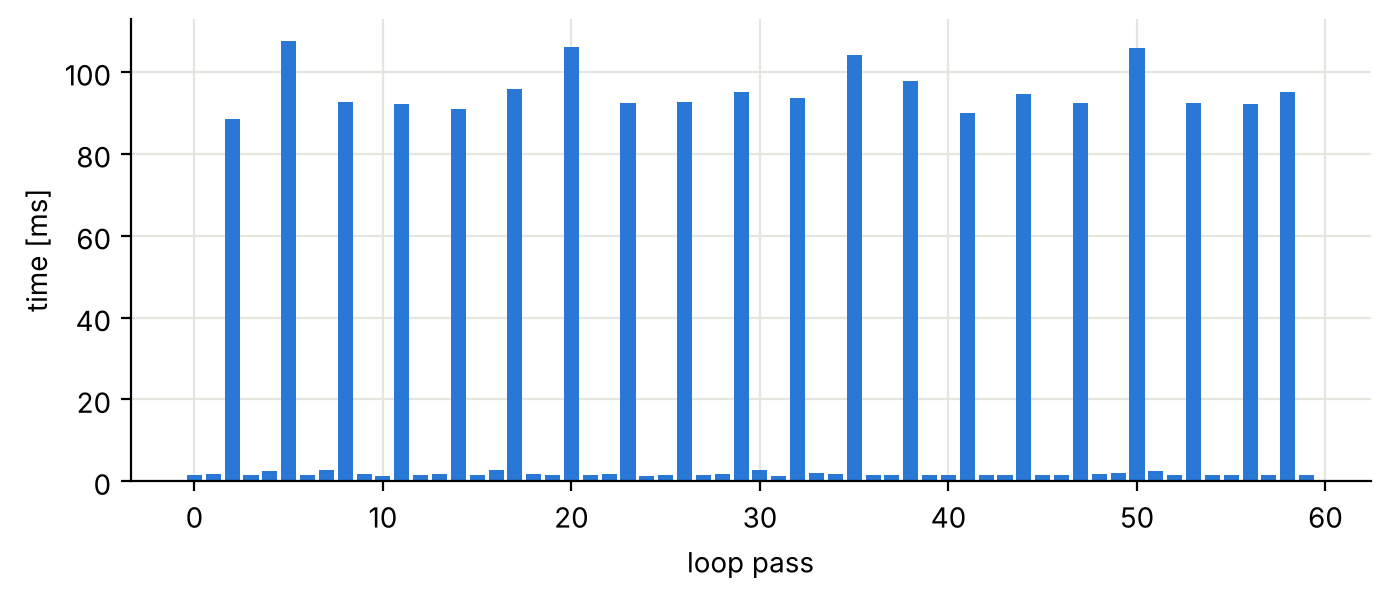

In [4]:
df = load("06_none_nodisplay.csv")
first_60 = df["frame_ms"].iloc[:60]

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(range(len(first_60)), first_60, color=BLUE)
ax.set_xlabel("loop pass")
ax.set_ylabel("time [ms]")
save(fig, "2_loop_pass_pattern.png")
plt.show()

## 3. Brightest spot: three implementations
Time of the detector call only, log scale.

In [5]:
methods = {
    "OpenCV": "09_detect_time_opencv.csv",
    "NumPy":  "10_detect_time_numpy.csv",
    "loop":   "11_detect_time_loop.csv",
}

names = list(methods.keys())
detect_ms = [load(f)["detect_ms"].mean() for f in methods.values()]
fps = [1000 / load(f)["frame_ms"].mean() for f in methods.values()]

table = pd.DataFrame({"detect_ms": detect_ms, "fps": fps}, index=names)
table["x_slower"] = table["detect_ms"] / table["detect_ms"]["OpenCV"]
table.round(3)

,detect_ms,fps,x_slower
OpenCV,0.036,30.026,1.000
NumPy,0.079,30.037,2.231
loop,32.458,25.821,912.721


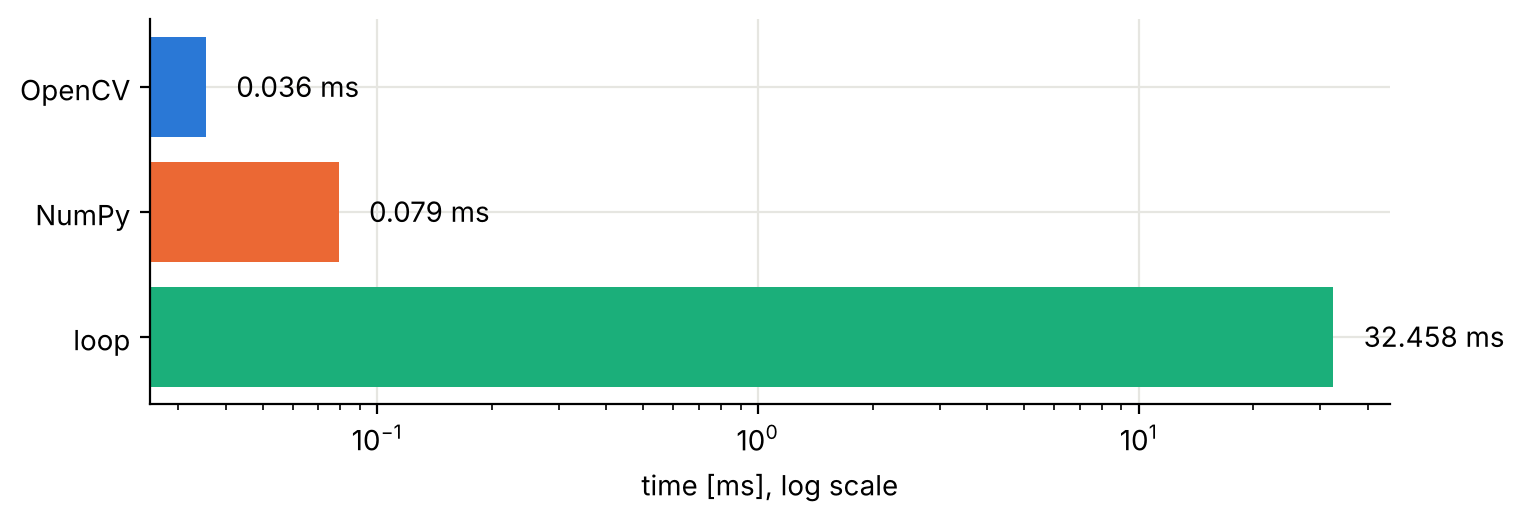

In [6]:
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.barh(names, detect_ms, color=[BLUE, ORANGE, GREEN])
ax.set_xscale("log")
ax.invert_yaxis()
ax.set_xlabel("time [ms], log scale")
for i, ms in enumerate(detect_ms):
    ax.text(ms * 1.2, i, f"{ms:.3f} ms", va="center")
save(fig, "3_brightest_methods.png")
plt.show()

## 4. Colours picked as reddest
Pixel colour at each detection, one column per frame.

In [7]:
def hex_to_rgb(hex_color):
    hex_color = hex_color.lstrip("#")
    return [int(hex_color[i:i + 2], 16) / 255 for i in (0, 2, 4)]


def colour_strips(df, columns, labels, filename):
    image = [[hex_to_rgb(h) for h in df[col]] for col in columns]

    fig, ax = plt.subplots(figsize=(9, 0.6 * len(columns) + 0.8))
    ax.imshow(image, aspect="auto", interpolation="nearest")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("frame")
    ax.grid(False)
    save(fig, filename)
    plt.show()

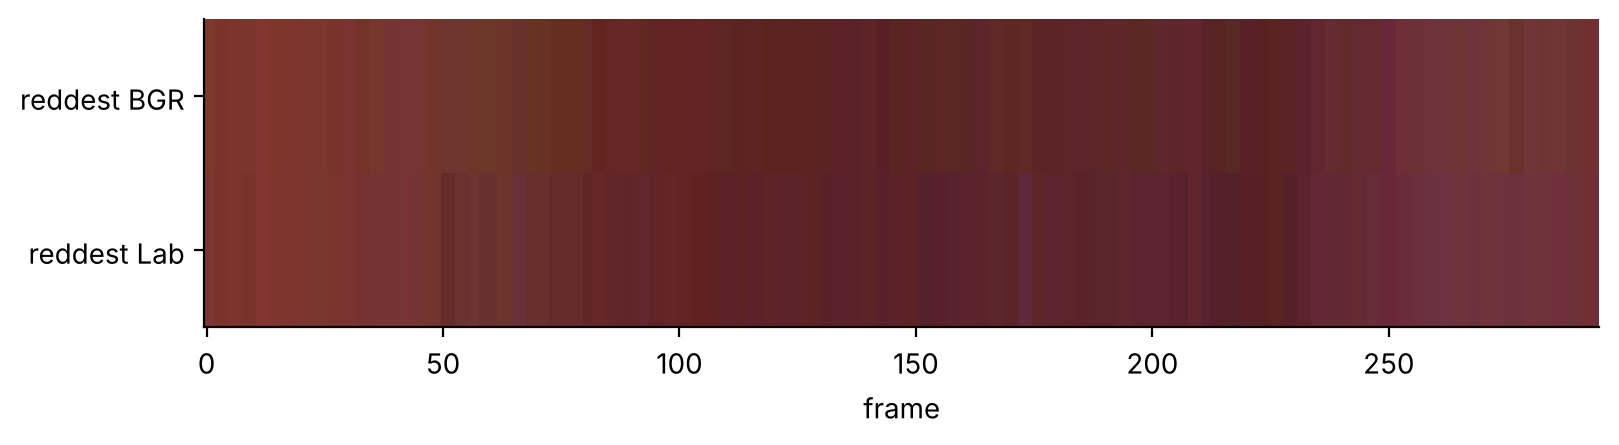

In [8]:
df_red = load("05_reddest_display.csv")
colour_strips(df_red,
              ["red_bgr_rgb", "red_lab_rgb"],
              ["reddest BGR", "reddest Lab"],
              "4a_reddest_colours.png")

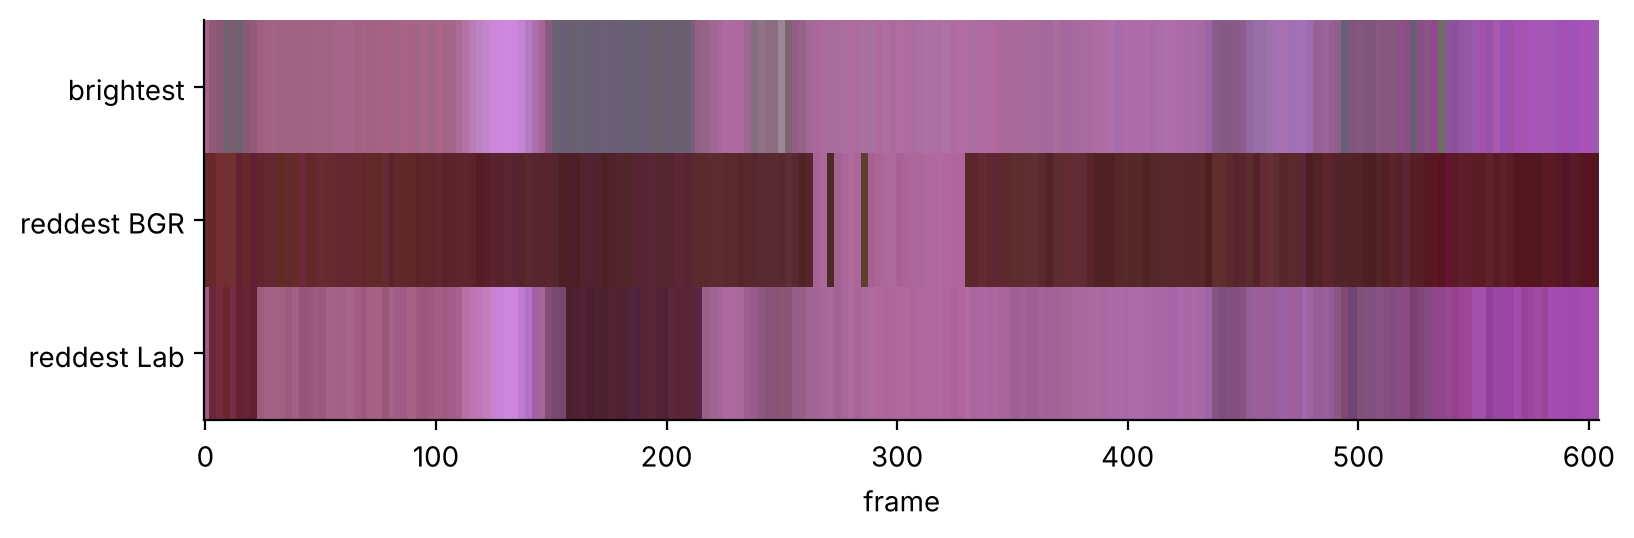

In [9]:
df_all = load("02_brightest_reddest_spots_opencv.csv")
colour_strips(df_all,
              ["bright_rgb", "red_bgr_rgb", "red_lab_rgb"],
              ["brightest", "reddest BGR", "reddest Lab"],
              "4b_all_colours.png")

## 5. Distance between the two red picks
Pixels between the BGR and Lab locations, per frame.

In [10]:
def distance(df):
    dx = df["red_bgr_x"] - df["red_lab_x"]
    dy = df["red_bgr_y"] - df["red_lab_y"]
    return np.sqrt(dx**2 + dy**2)


d_red = distance(df_red)
d_all = distance(df_all)

print(f"reddest run:  {(d_red > 20).mean():.0%} of frames more than 20 px apart")
print(f"combined run: {(d_all > 20).mean():.0%} of frames more than 20 px apart")

reddest run:  26% of frames more than 20 px apart
combined run: 85% of frames more than 20 px apart


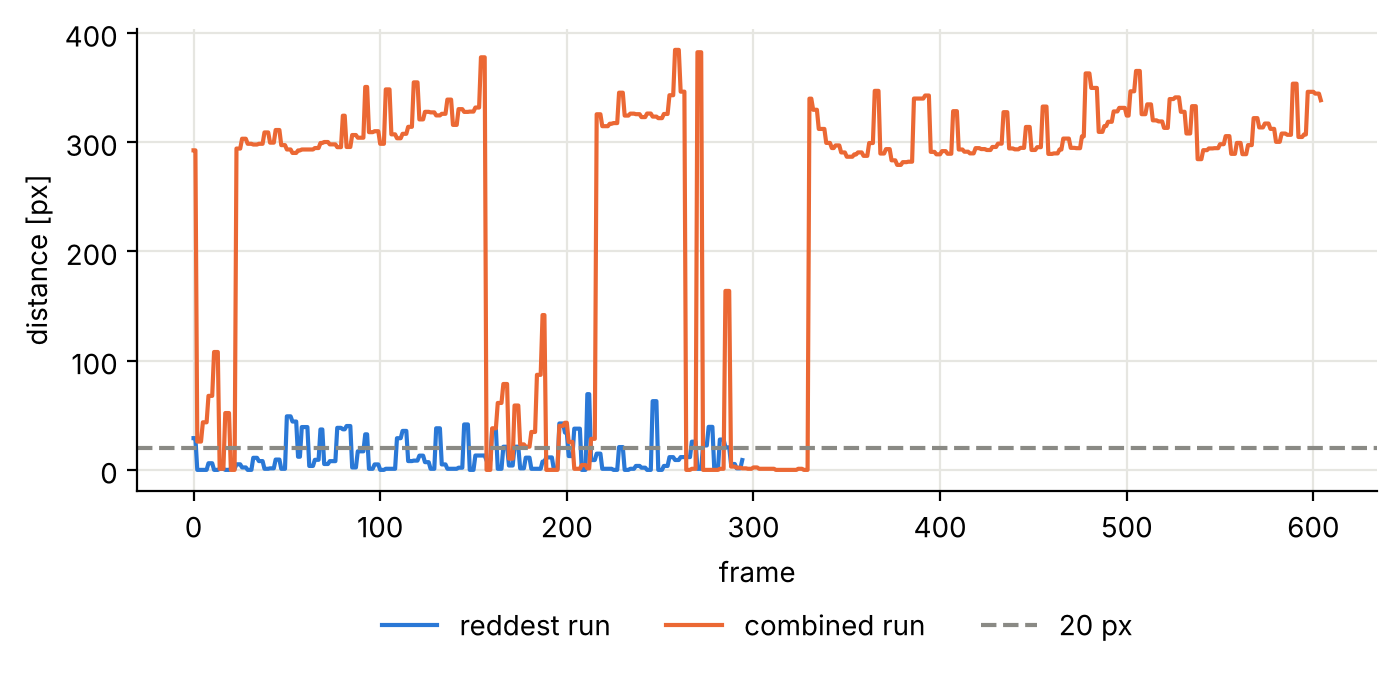

In [11]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(d_red.to_numpy(), color=BLUE, label="reddest run")
ax.plot(d_all.to_numpy(), color=ORANGE, label="combined run")
ax.axhline(20, color=GRAY, linestyle="--", label="20 px")
ax.set_xlabel("frame")
ax.set_ylabel("distance [px]")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
save(fig, "5_red_disagreement.png")
plt.show()